# Flask Expression Analysis — Summary & SI Report

End-to-end summary of the flask-scale LC-MS RiPP-modification experiments. The
notebook runs top-to-bottom as a single pipeline:

| Section | What it does |
|---------|--------------|
| **1. Setup** | Imports and all configuration in one place (paths, the plasmid keep-list, SI caption). |
| **2. Load reports** | Build the long-form `master_df` from every curated `*_manually_reviewed.pkl.gz`. |
| **3. Select plasmids** | Split into the **decided-on** set (`kept_df`) and everything else (`dropped_df`) using one explicit `KEEP_PLASMIDS` list. |
| **4. Modification ratios** | Pick the best cut/charge per group, collapse to a per-replicate `mod_ratio`, and derive the tag / core / leader columns used for grouping. |
| **5. Bar plots** | Grouped sequence-alignment + modification-ratio bar charts for the decided-on set, kept separated by solubility tag and core. |
| **6. SI report** | Generate and combine the per-group SI PDF pages, in the keep-list order. |
| **7. Filtered-out data** | The same bar plots for the plasmids that were *not* in the keep-list. |
| **8. Appendix** | Legacy helpers and single-peak / MS² inspection snippets (dormant). |

> **Data lives on `D:\`** and rendering the alignments calls MUSCLE, so this
> notebook is meant to be run against the real analysis outputs, not a checkout.

## 1. Setup — imports & configuration

Everything that a run might need to be pointed at a different dataset or a
different plasmid selection lives in this one cell.

In [1]:
# --- Imports ---
import re
import pickle
from pathlib import Path

import pandas as pd

import analysis_containers
import plotting_analysis_functions
from plotting_analysis_functions import (
    build_master_dataframe_from_groups,
    get_ordered_source_files,
    natural_sort_key,
    extract_best_cut_charge,
    collapse_modification_replicates,
    create_grouped_alignment_plot,
    generate_and_combine_simple_si_reports,
)
from analysis_containers import ReplicateGroupResults, AnalysisResults

In [2]:
# --- Configuration ---------------------------------------------------------------

# Where the curated per-group ReplicateGroupResults pickles live.
REPORTS_PATH = r"D:\Spliceotide_Data_Analysis\output_reports_flasks"

# Combined SI PDF destination.
COMBINED_SI_PDF_PATH = r"D:\Spliceotide_Data_Analysis\output_reports_plates\SI_reports\combined_SI_report_flasks_A.pdf"

# Where processed summary tables / plots are written.
SUMMARY_DIR = Path("summary_data_files")

# The plasmids we decided on -------------------------------------------------------
# This single list is the source of truth for the whole notebook. It is matched
# against the `precursor_plasmid` column of master_df: any group whose precursor
# plasmid is in this list is "kept" (bar plots + SI report); everything else is
# routed to the "filtered-out" section further down.
#
# The list order is *also* the SI page / display order, so it is intentionally NOT
# a plain numeric sort (the 693-700 block is placed before the 674-679 block).
KEEP_PLASMIDS = [
    "TJ-C-593", "TJ-C-594", "TJ-C-595", "TJ-C-596", "TJ-C-597", "TJ-C-598", "TJ-C-599", # wild type Hyella
    "TJ-C-614", "TJ-C-617", "TJ-C-618", "TJ-C-619", "TJ-C-620", # consensus Hyella
    "TJ-C-693", "TJ-C-694", "TJ-C-695", "TJ-C-696", "TJ-C-697", "TJ-C-698", "TJ-C-699", "TJ-C-700", # artificial
    "TJ-C-674", "TJ-C-675", "TJ-C-676", "TJ-C-677", "TJ-C-678", "TJ-C-679", # HypAc with trunc PlpA3 variants
    "TJ-C-680", "TJ-C-681", "TJ-C-682", "TJ-C-683", "TJ-C-684", "TJ-C-685" # PlpA3 with trunc PlpA3 variants
]
KEEP_RANK = {plasmid: i for i, plasmid in enumerate(KEEP_PLASMIDS)}

# Extra exclusion: remove any samples with plasmids in the range 593-620 where the
# digestion is TEV (these plasmids are still kept for every other digestion). The
# bound is inclusive on both ends and matched on the numeric part of the plasmid id.
TEV_EXCLUDE_RANGE = (593, 620)

def _plasmid_number(plasmid):
    """Numeric part of a 'TJ-C-###' id, or None if it has no digits."""
    match = re.search(r"(\d+)", str(plasmid))
    return int(match.group(1)) if match else None

def keep_mask(df):
    """Boolean row-mask for the decided-on set: precursor plasmid in KEEP_PLASMIDS,
    minus TEV-digested samples whose plasmid number is within TEV_EXCLUDE_RANGE.
    Used for both master_df and the modification-ratio table so the bar plots and
    the SI report always agree on which samples are in vs out."""
    in_keep = df["precursor_plasmid"].isin(KEEP_PLASMIDS)
    numbers = pd.to_numeric(df["precursor_plasmid"].map(_plasmid_number), errors="coerce")
    in_range = numbers.between(*TEV_EXCLUDE_RANGE)
    is_tev = df["digestion"].astype(str).str.contains("TEV", case=False, na=False)
    return in_keep & ~(in_range & is_tev)

# SI figure caption. Flask data is "SI Appendix A" (the plate notebook uses the
# module default "SI Appendix B"); wording/fields otherwise match so the two stay
# in sync.
FLASK_SI_CAPTION_TEMPLATE = (
    "SI Appendix A Figure {i}: Results of coexpression of plasmid {precursor_plasmid} with "
    "{maturase_plasmid} at {expression_temperature}\u00b0C for {expression_time} h in "
    "{expression_scale} [mL] of culture volume, the precursor is {precursor_name} and was "
    "digested using {digestion}. The fragment shown ranges from {cut_start} to {cut_end} and "
    "charge state z={charge} is plotted"
)

print(f"{len(KEEP_PLASMIDS)} plasmid(s) in the keep-list.")

32 plasmid(s) in the keep-list.


## 2. Load all reports → `master_df`

`build_master_dataframe_from_groups()` walks `REPORTS_PATH`, loads every group's
curated `ReplicateGroupResults`, and returns one long-form row per
(replicate × fragment_cut × charge × modification) — including stub placeholders
for states that were never detected. Experiment metadata (precursor/maturase
plasmid, temperature, digestion, core coordinates, …) is pulled straight off each
replicate's `MSExperiment`, so no separate metadata merge is needed.

In [3]:
master_df = build_master_dataframe_from_groups(REPORTS_PATH)

print(f"master_df: {len(master_df):,} rows, {master_df['group_name'].nunique()} group(s), "
      f"{master_df['precursor_plasmid'].nunique()} precursor plasmid(s).")
master_df.head()

Found 78 manually reviewed group file(s) under: D:\Spliceotide_Data_Analysis\output_reports_flasks
Successfully loaded ReplicateGroupResults from: D:\Spliceotide_Data_Analysis\output_reports_flasks\artificial_peptides_TJ-C-674_HypX-HypY_TJ-C-560_24_TEV\artificial_peptides_TJ-C-674_HypX-HypY_TJ-C-560_24_TEV_manually_reviewed.pkl.gz
Successfully loaded ReplicateGroupResults from: D:\Spliceotide_Data_Analysis\output_reports_flasks\artificial_peptides_TJ-C-674_HypX-HypY_TJ-C-560_30_TEV\artificial_peptides_TJ-C-674_HypX-HypY_TJ-C-560_30_TEV_manually_reviewed.pkl.gz
Successfully loaded ReplicateGroupResults from: D:\Spliceotide_Data_Analysis\output_reports_flasks\artificial_peptides_TJ-C-675_HypX-HypY_TJ-C-560_24_TEV\artificial_peptides_TJ-C-675_HypX-HypY_TJ-C-560_24_TEV_manually_reviewed.pkl.gz
Successfully loaded ReplicateGroupResults from: D:\Spliceotide_Data_Analysis\output_reports_flasks\artificial_peptides_TJ-C-676_HypX-HypY_TJ-C-560_24_TEV\artificial_peptides_TJ-C-676_HypX-HypY_TJ-C-5

,replicate_id,fragment_cut,charge,modification,absolute_area,rt,qc_score,is_stub,overall_signal_intensity,relative_area,...,cut_id,area,modification_state,target_sequence,peptide_sequence_meta,enzyme,_source_file,_source_path,quality_score,tier
0,artificial_peptides_TJ-C-674_HypX-HypY_TJ-C-56...,"(207, 223)",1,{'Unmodified': True},2.001552e+06,9.223374,6.521974,False,2.001552e+06,1.0,...,"(207, 223)",2.001552e+06,{'Unmodified': True},MSYYHHHHHHGSLQDSEVNQEAKPEVKPEVKPETHINLKVSDGSSE...,MSYYHHHHHHGSLQDSEVNQEAKPEVKPEVKPETHINLKVSDGSSE...,HypX-HypY,artificial_peptides_TJ-C-674_HypX-HypY_TJ-C-56...,D:\Spliceotide_Data_Analysis\output_reports_fl...,0.792142,Silver
1,artificial_peptides_TJ-C-674_HypX-HypY_TJ-C-56...,"(207, 223)",1,{'Unmodified': True},2.580160e+06,9.219970,1.267679,False,2.580160e+06,1.0,...,"(207, 223)",2.580160e+06,{'Unmodified': True},MSYYHHHHHHGSLQDSEVNQEAKPEVKPEVKPETHINLKVSDGSSE...,MSYYHHHHHHGSLQDSEVNQEAKPEVKPEVKPETHINLKVSDGSSE...,HypX-HypY,artificial_peptides_TJ-C-674_HypX-HypY_TJ-C-56...,D:\Spliceotide_Data_Analysis\output_reports_fl...,0.980742,Gold
2,artificial_peptides_TJ-C-674_HypX-HypY_TJ-C-56...,"(207, 223)",2,{'Unmodified': True},8.573461e+06,9.214985,6.309286,False,8.573461e+06,1.0,...,"(207, 223)",8.573461e+06,{'Unmodified': True},MSYYHHHHHHGSLQDSEVNQEAKPEVKPEVKPETHINLKVSDGSSE...,MSYYHHHHHHGSLQDSEVNQEAKPEVKPEVKPETHINLKVSDGSSE...,HypX-HypY,artificial_peptides_TJ-C-674_HypX-HypY_TJ-C-56...,D:\Spliceotide_Data_Analysis\output_reports_fl...,0.804180,Silver
3,artificial_peptides_TJ-C-674_HypX-HypY_TJ-C-56...,"(207, 223)",2,{'Unmodified': True},1.156344e+07,9.254474,1.198074,False,1.156344e+07,1.0,...,"(207, 223)",1.156344e+07,{'Unmodified': True},MSYYHHHHHHGSLQDSEVNQEAKPEVKPEVKPETHINLKVSDGSSE...,MSYYHHHHHHGSLQDSEVNQEAKPEVKPEVKPETHINLKVSDGSSE...,HypX-HypY,artificial_peptides_TJ-C-674_HypX-HypY_TJ-C-56...,D:\Spliceotide_Data_Analysis\output_reports_fl...,0.980609,Gold
4,artificial_peptides_TJ-C-674_HypX-HypY_TJ-C-56...,"(207, 223)",2,{'Unmodified': True},3.747481e+06,9.261536,1.421078,False,3.747481e+06,1.0,...,"(207, 223)",3.747481e+06,{'Unmodified': True},MSYYHHHHHHGSLQDSEVNQEAKPEVKPEVKPETHINLKVSDGSSE...,MSYYHHHHHHGSLQDSEVNQEAKPEVKPEVKPETHINLKVSDGSSE...,HypX-HypY,artificial_peptides_TJ-C-674_HypX-HypY_TJ-C-56...,D:\Spliceotide_Data_Analysis\output_reports_fl...,0.982722,Gold


## 3. Select the plasmids we decided on

Split `master_df` into the decided-on set and the rest using `KEEP_PLASMIDS`.
The kept rows are sorted into the keep-list order (then by maturase and digestion)
so the SI report pages come out in exactly that sequence.

- **`kept_df`** — drives the bar plots (Section 5) and the SI report (Section 6).
- **`dropped_df`** — plotted on its own in Section 7.
- **`ordered_source_file_list`** — one source pickle per kept group, in keep-list order.

In [4]:
keep_row_mask = keep_mask(master_df)
kept_df = master_df[keep_row_mask].copy()
dropped_df = master_df[~keep_row_mask].copy()

# Sort kept rows into the explicit keep-list order (fillna keeps the secondary
# string columns comparable when digestion/maturase is missing).
kept_df["_keep_rank"] = kept_df["precursor_plasmid"].map(KEEP_RANK)
kept_df = kept_df.sort_values(
    ["_keep_rank", "maturase_name", "digestion"],
    key=lambda s: natural_sort_key(s.fillna("")),
)

# One source pickle per kept group, already in the desired order (dedup in place).
ordered_source_file_list = get_ordered_source_files(kept_df, sort_cols=None)

# Report which requested plasmids never showed up in the data, for transparency.
present = set(master_df["precursor_plasmid"].unique())
missing = [p for p in KEEP_PLASMIDS if p not in present]

# How many rows the TEV/593-620 rule removed from the otherwise-kept set.
n_tev_excluded = int((master_df["precursor_plasmid"].isin(KEEP_PLASMIDS) & ~keep_row_mask).sum())

print(f"Kept:    {kept_df['group_name'].nunique()} group(s) across "
      f"{kept_df['precursor_plasmid'].nunique()} plasmid(s).")
print(f"Dropped: {dropped_df['group_name'].nunique()} group(s) across "
      f"{dropped_df['precursor_plasmid'].nunique()} plasmid(s).")
print(f"{len(ordered_source_file_list)} kept group(s) ordered for SI generation.")
print(f"TEV/593-620 rule removed {n_tev_excluded} row(s) from the keep-list set "
      f"(routed to the filtered-out section).")
if missing:
    print(f"NOTE: {len(missing)} keep-list plasmid(s) not found in the reports: {missing}")

Kept:    49 group(s) across 32 plasmid(s).
Dropped: 24 group(s) across 16 plasmid(s).
49 kept group(s) ordered for SI generation.
TEV/593-620 rule removed 0 row(s) from the keep-list set (routed to the filtered-out section).


## 4. Modification-ratio dataframe

1. **`extract_best_cut_charge()`** — per group, pick the single (cut, charge) seen
   in the most replicates (ties broken by average area, then quality).
2. **`collapse_modification_replicates()`** — collapse each replicate to its
   unmodified peptide and compute `mod_ratio` = 1 − (unmodified area / total signal).
   Replicates whose *unmodified* peak was never detected get `mod_ratio = NaN`
   (a missed peak is not the same as full conversion).
3. **Derived columns** — `full_core_sequence`, `solubility_tag`, `core_name`,
   `leader`, `core` — used to group and label the bar plots.

The full table is pickled unchanged for downstream consumers, then split into the
kept / dropped views by `precursor_plasmid`.

In [5]:
# Step 1 + 2: best cut/charge per group, then per-replicate modification ratio.
best_cut_charge_df = extract_best_cut_charge(master_df)
processed_ratios_df = collapse_modification_replicates(best_cut_charge_df)

print(f"Calculated modification ratios for {len(processed_ratios_df)} feature(s).")

[collapse_modification_replicates] 5 of 125 replicate(s) have an undetected (stub) unmodified peptide -> mod_ratio set to NaN (cannot distinguish full conversion from a missed peak).
Calculated modification ratios for 125 feature(s).


In [6]:
# Step 3: derived grouping / labelling columns.

# Full core sequence: from core_start-1 (0-based, -2 keeps the residue before the
# cut) to the end of the metadata peptide sequence, with stop codons stripped.
processed_ratios_df["full_core_sequence"] = processed_ratios_df.apply(
    lambda row: row["peptide_sequence_meta"][int(row["core_start"]) - 2:],
    axis=1,
)
processed_ratios_df["full_core_sequence"] = (
    processed_ratios_df["full_core_sequence"].str.replace("*", "", regex=False)
)

# Solubility tag parsed out of the precursor name (longest/most-specific first).
tag_names = ["Fh8-chaos", "Fh8", "RSTN", "Pfu-MBP", "sfGFP", "Fka-MTR"]
processed_ratios_df["solubility_tag"] = processed_ratios_df["precursor_name"].apply(
    lambda x: next((tag for tag in tag_names if tag in x), "None")
)

# Pretty temperature label for the plot metadata column.
processed_ratios_df["expression_temperature_fancy"] = (
    processed_ratios_df["expression_temperature"].apply(lambda x: f"{x}\u00b0C")
)

def split_leader_core_name(x):
    """Core name = the precursor name after its leader prefix. Falls back to the
    full name if no known leader prefix matches (keeps the pipeline robust to
    unexpected precursor names instead of raising)."""
    if not isinstance(x, str):
        return None, x

    y = x.replace("pACYC-K-T7-lacO-ElvJ-100k","")
    z = y.replace("pACYC-K-T7-lacO-ElvJ", "")
    a = z.replace("pACYC-K-T7-lacO-PP1", "")
    b = a.replace("pACYC-K-T7-lacO", "")
    splitted = b.split("-")

    # Search for TEV
    if "TEV" in splitted:
        tev_index = splitted.index("TEV")
        # Remove leading hyphen/character if needed before appending -TEV
        solubility_leader = "-".join(splitted[0:tev_index]).lstrip("-") + "-TEV"
        core = "-".join(splitted[tev_index + 1 :])
        return solubility_leader, core

    # Handle regex matches
    if re.search("HypAc", x):
        return "HypAc", x.split("HypAc-")[-1]

    match = re.search(r"HypA[1-9]-", x)
    if match:
        # Uses actual matched string for splitting rather than literal 'HypA[1-9]-'
        return match.group(0).rstrip("-"), x.split(match.group(0))[-1]

    # Fallback to ensure function always returns a 2-tuple
    return None, x

processed_ratios_df[["leader", "core_name"]] = pd.DataFrame(
    processed_ratios_df["precursor_name"].apply(split_leader_core_name).tolist(),
    index=processed_ratios_df.index,
)

# Persist the full processed table (unchanged name/location for downstream use).
SUMMARY_DIR.mkdir(exist_ok=True)
processed_ratios_df.to_pickle(SUMMARY_DIR / "flask_expressions_processed_ratios_df.pkl")

In [7]:
# Split the ratio table with the same rule as master_df (keep_mask).
ratio_keep_mask = keep_mask(processed_ratios_df)
kept_ratios_df = processed_ratios_df[ratio_keep_mask].copy()
dropped_ratios_df = processed_ratios_df[~ratio_keep_mask].copy()

print(f"kept_ratios_df:    {len(kept_ratios_df)} feature(s)")
print(f"dropped_ratios_df: {len(dropped_ratios_df)} feature(s)")

kept_ratios_df:    100 feature(s)
dropped_ratios_df: 25 feature(s)


## 5. Modification bar plots (decided-on set)

Each plot from `create_grouped_alignment_plot()` shows, per row: the aligned core
sequence (left, coloured by hydrophobicity) next to a horizontal **modification-ratio
bar** (0–1). Rows are grouped by the `metadata_cols` labels on the far left and
coloured by `hue_column`, so the separation into **solubility tags** and **cores**
stays visible. All plots below draw from `kept_ratios_df`.

### 5a. Artificial cores

`artificial_peptides` = every kept feature whose precursor is an artificial /
Boc- / LQYG construct. `solubility_tags` narrows that to the two cores compared
across solubility tags.

In [8]:
artificial_peptides = kept_ratios_df[
    (kept_ratios_df["precursor_name"].str.contains("Artificial")) |
    (kept_ratios_df["precursor_name"].str.contains("Boc-")) |
    (kept_ratios_df["precursor_name"].str.contains("LQYG"))
]

solubility_tags = kept_ratios_df[
    kept_ratios_df["core_name"].isin(["Artificial-2", "PlpA3-Boc-Trunc", "PlpA3-Trunc"])
]

print(f"artificial_peptides: {len(artificial_peptides)} | solubility_tags: {len(solubility_tags)}")

artificial_peptides: 39 | solubility_tags: 39


**Overview — all artificial cores**, grouped by temperature · solubility tag · core.

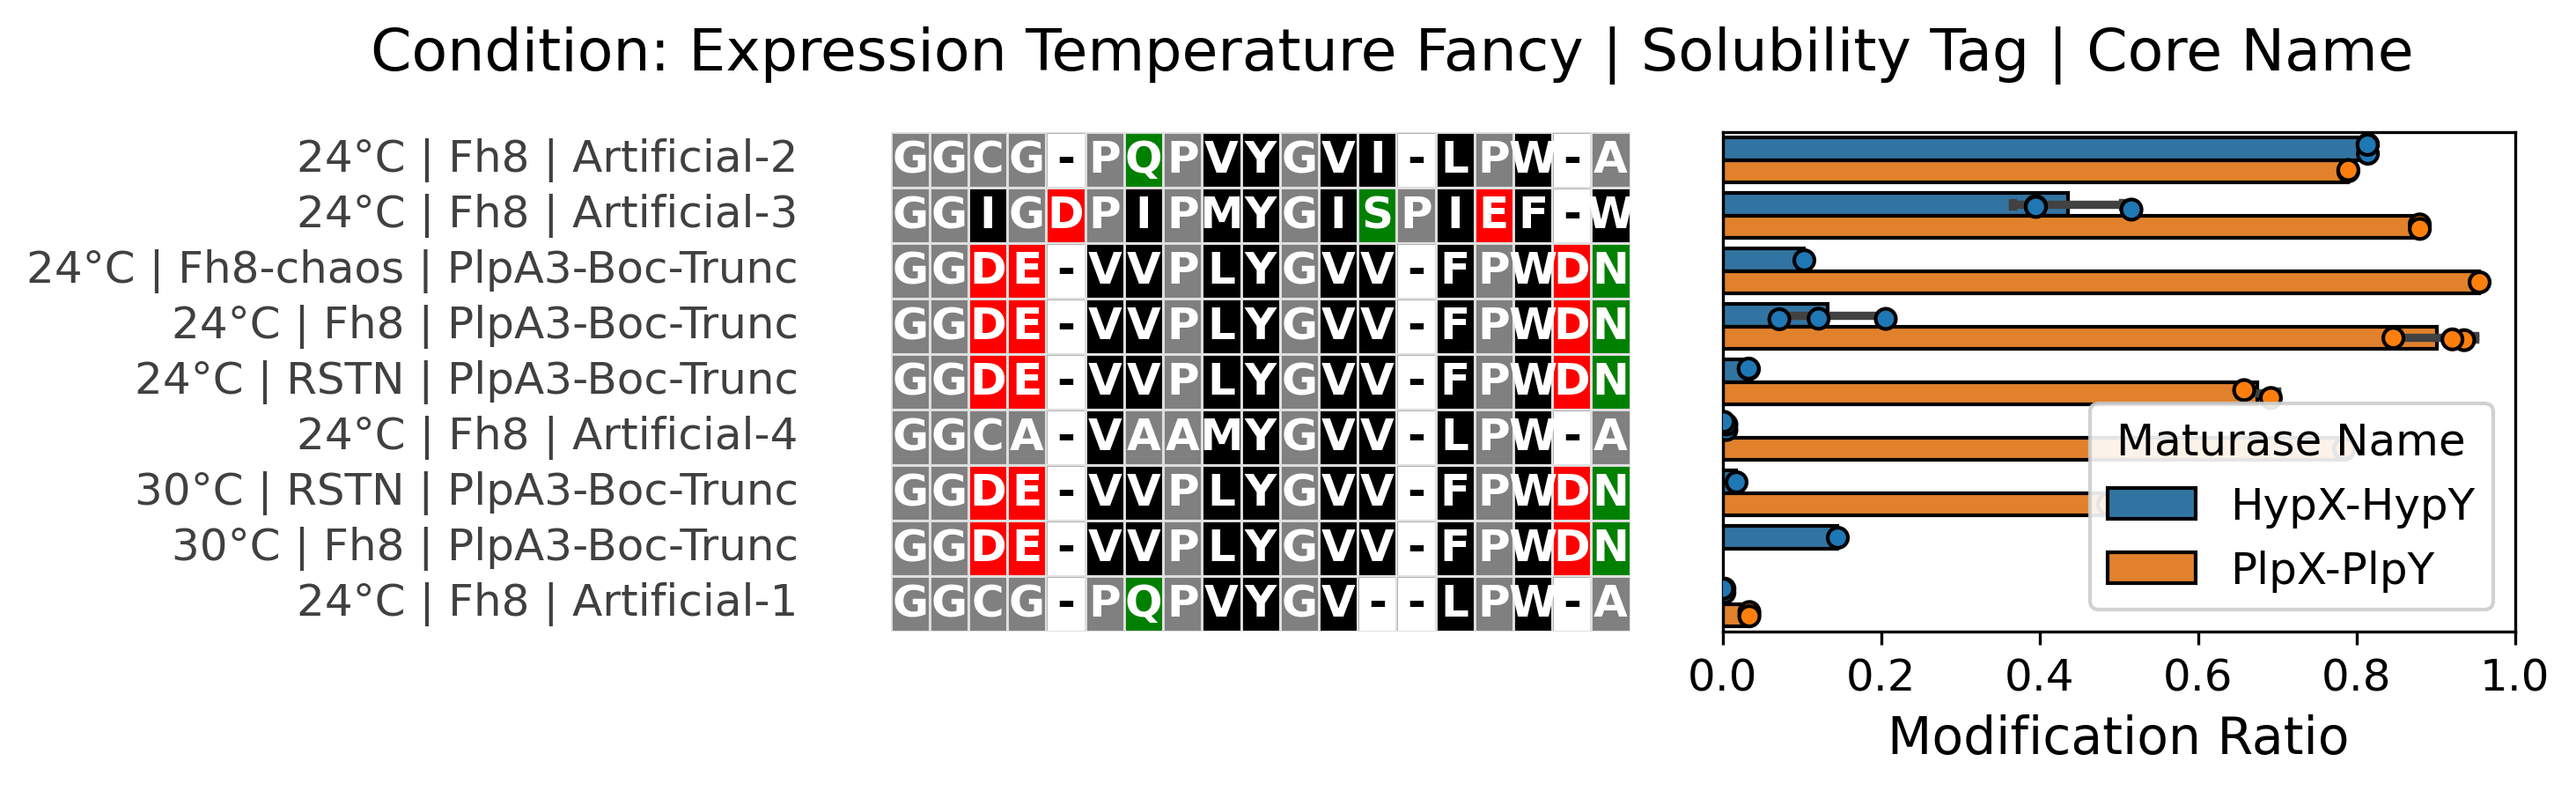

In [9]:
create_grouped_alignment_plot(
    artificial_peptides,
    ref_sequence="GGCGPQPVYGVILPWA",
    metadata_cols=["expression_temperature_fancy", "solubility_tag", "core_name"],
    color_scheme_name="hydrophobicity",
    show_ddg=False,
    preset="poster",
    savepath=None,
    show_gaps=True,
    use_alignment=True,
    drop_identical=False,
    sequence_column="full_core_sequence",
)

**Fh8 tag at 24 °C**, one row per core (saved as `flask_artificial_peptides.eps`).

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


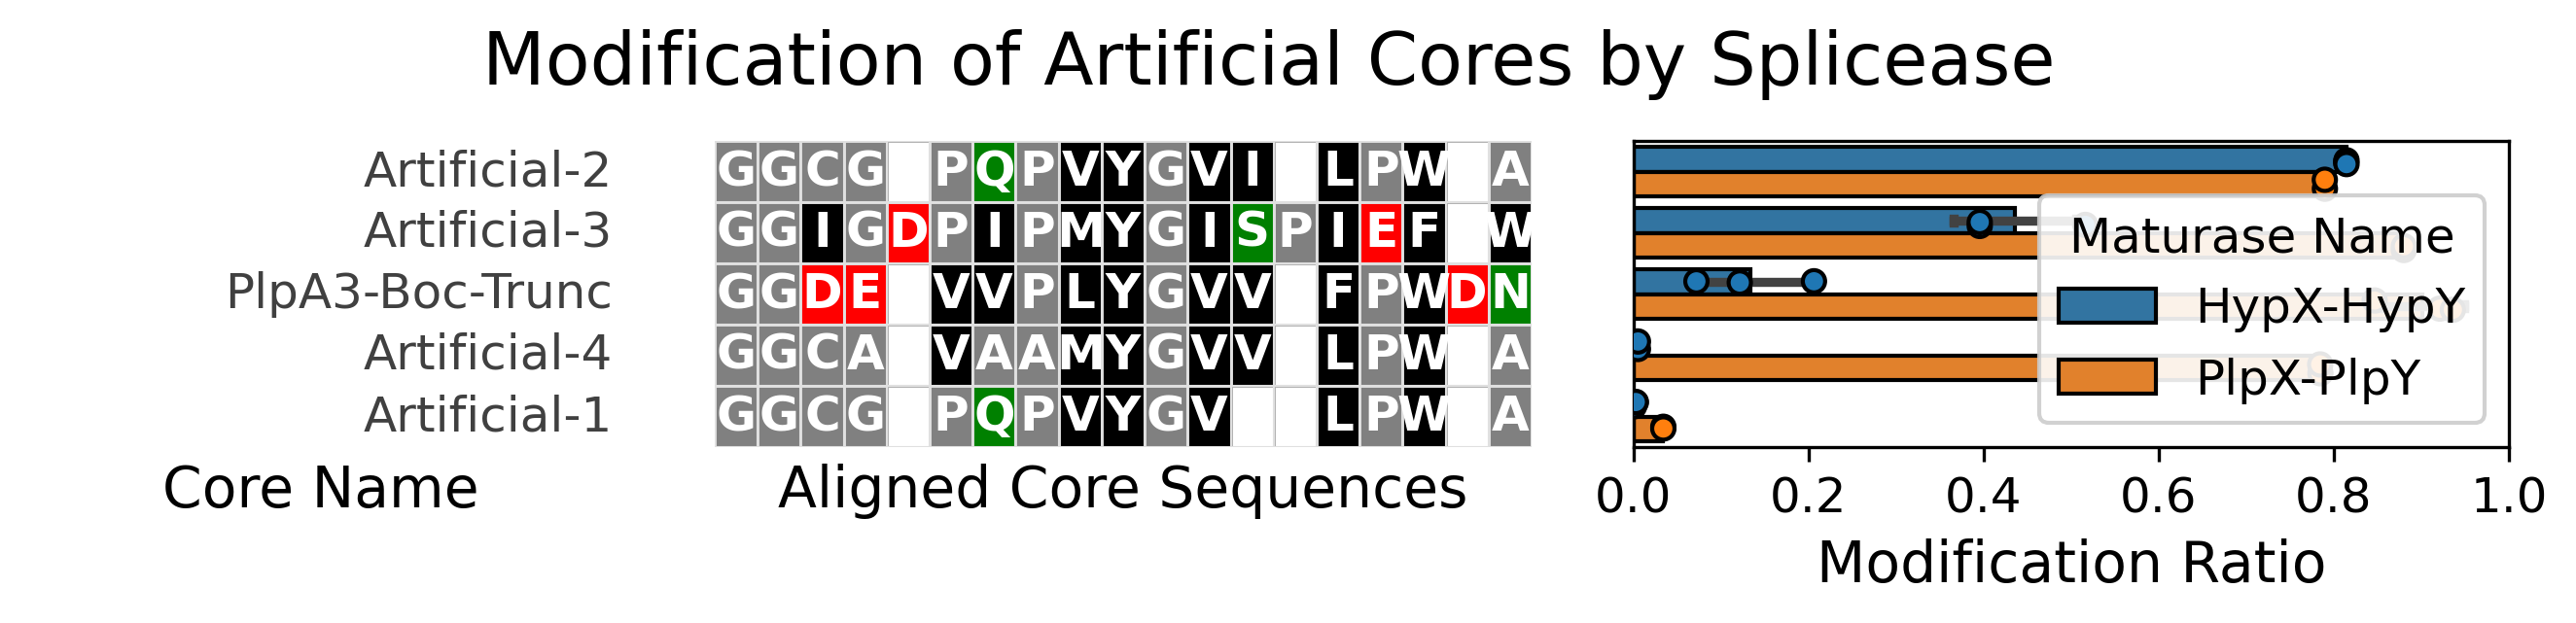

In [10]:
create_grouped_alignment_plot(
    artificial_peptides[
        (artificial_peptides["solubility_tag"] == "Fh8")
        & (artificial_peptides["expression_temperature"] == 24)
    ].sort_values("core_name"),
    ref_sequence="GGCGPQPVYGVILPWA",
    metadata_cols=["core_name"],
    color_scheme_name="hydrophobicity",
    show_ddg=False,
    preset="poster",
    savepath="summary_data_files/flask_artificial_peptides.eps",
    use_alignment=True,
    drop_identical=False,
    seqtitle="Aligned Core Sequences",
    metatitle="Core Name",
    suptitle="Modification of Artificial Cores by Splicease",
    sequence_column="full_core_sequence",
)

### 5b. Solubility-tag comparison

The two artificial cores across every solubility tag / temperature
(saved as `flask_artificial_2_solubility_peptides.eps`). `drop_identical=True`
blanks residues that match the reference so only differences stand out.

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


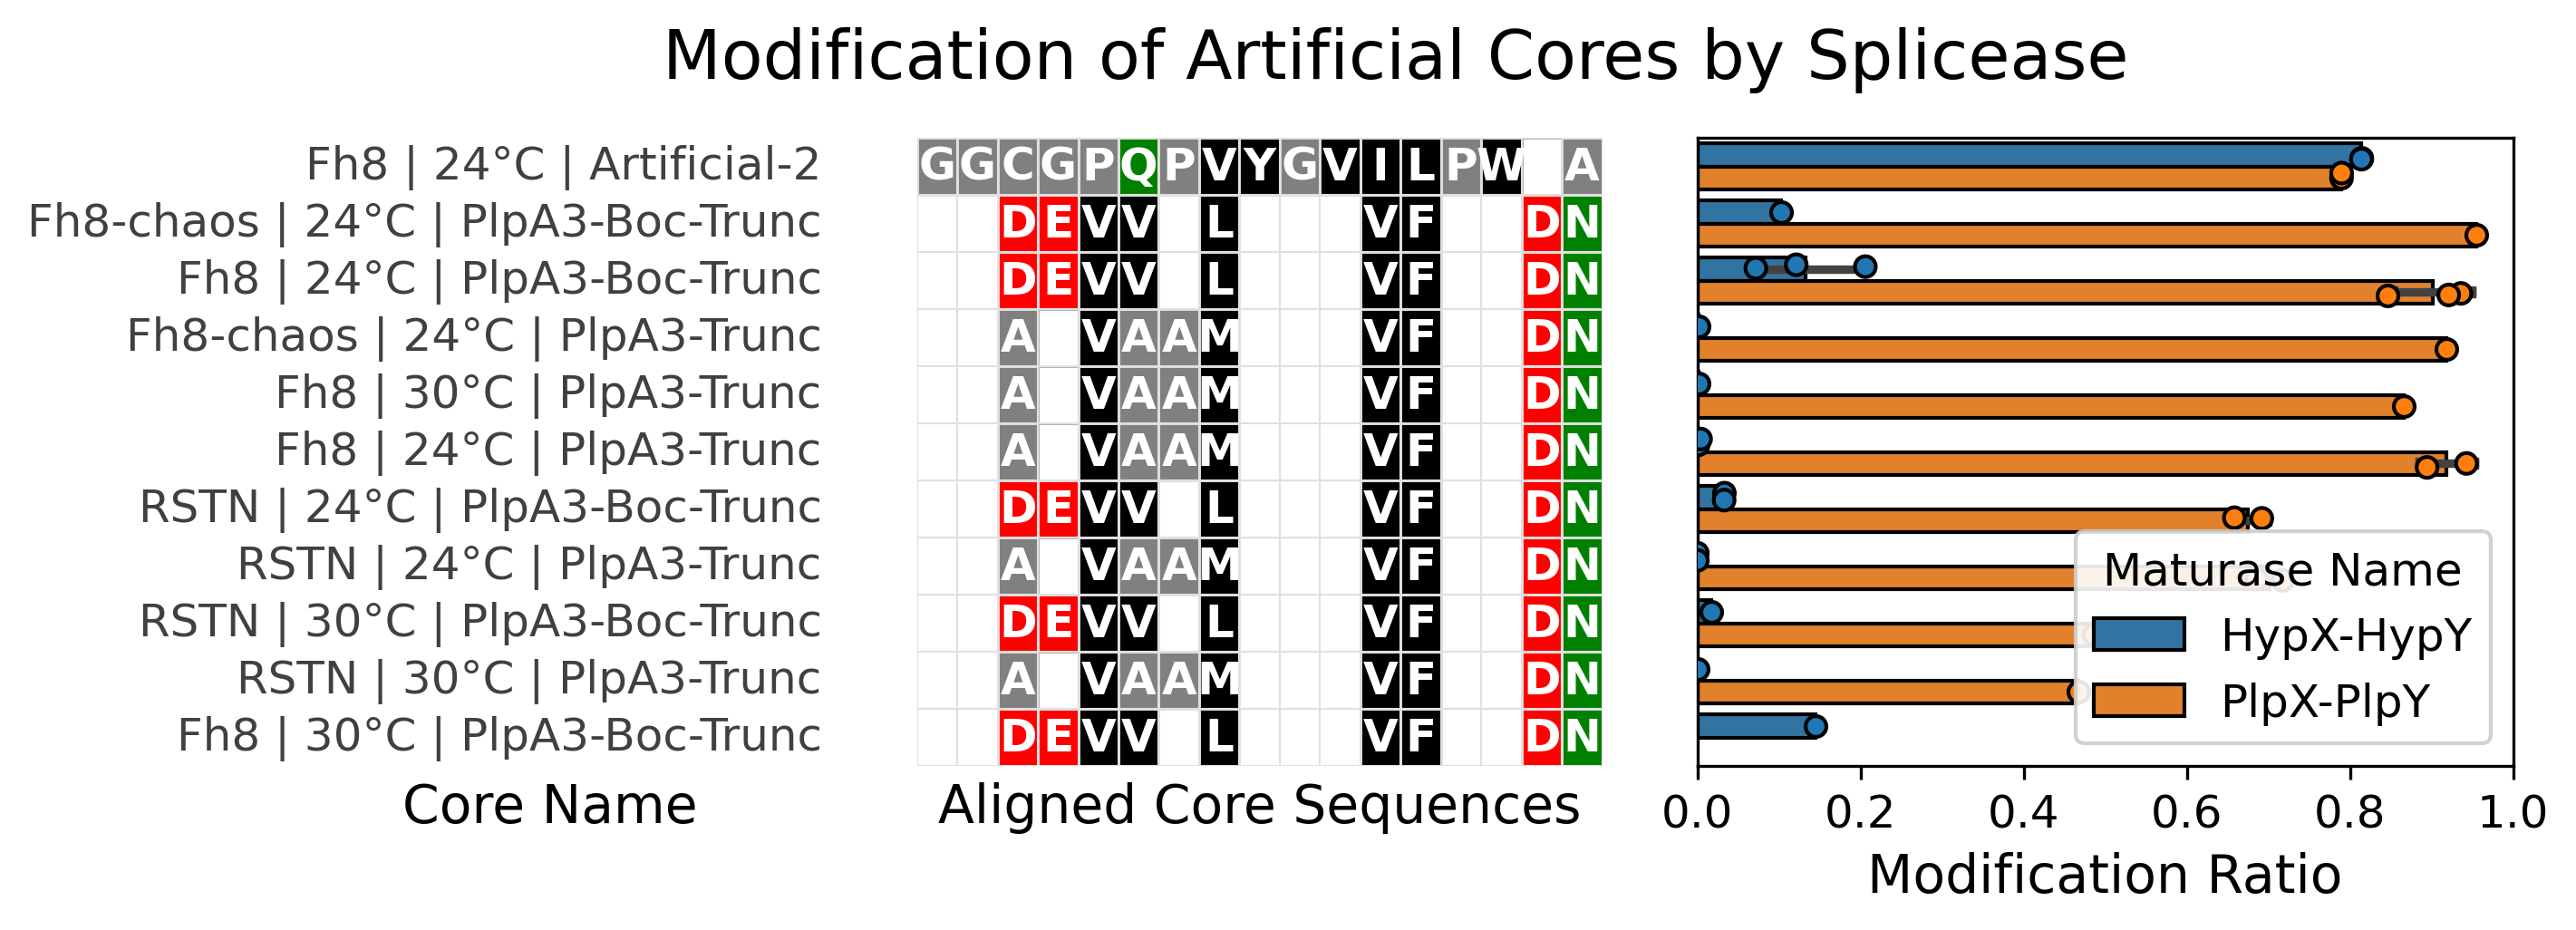

In [11]:
create_grouped_alignment_plot(
    solubility_tags,
    ref_sequence="GGCGPQPVYGVILPWA",
    metadata_cols=["solubility_tag", "expression_temperature_fancy", "core_name"],
    color_scheme_name="hydrophobicity",
    show_ddg=False,
    preset="poster",
    savepath="summary_data_files/flask_artificial_2_solubility_peptides.eps",
    use_alignment=True,
    drop_identical=True,
    seqtitle="Aligned Core Sequences",
    metatitle="Core Name",
    suptitle="Modification of Artificial Cores by Splicease",
    sequence_column="full_core_sequence",
)

### 5c. Convenience subsets (artificial, by maturase)

Handy pre-filtered views for ad-hoc plotting — not drawn by default.

In [12]:
artificial_peptides_plp = kept_ratios_df[
    (kept_ratios_df["maturase_name"] == "PlpX-PlpY")
    & (kept_ratios_df["precursor_name"].str.contains("Artificial"))
]

artificial_peptides_hyp = kept_ratios_df[
    (kept_ratios_df["maturase_name"] == "HypX-HypY")
    & (kept_ratios_df["precursor_name"].str.contains("Artificial"))
]

print(f"PlpX-PlpY: {len(artificial_peptides_plp)} | HypX-HypY: {len(artificial_peptides_hyp)}")

PlpX-PlpY: 8 | HypX-HypY: 12


### 5d. Wild-type consensus (Hyella)

Wild-type / consensus Hyella core fusions modified by HypX-HypY. Two zero-ratio
control rows (the native cluster precursors PlpA2 / PlpA3) are appended so the
plots show the reference cores alongside the fusions. Split by maturase plasmid:
`TJ-C-689` (consensus leader) and `TJ-C-560` (native precursors).

In [13]:
wild_type_peptides_hyella = kept_ratios_df[
    (kept_ratios_df["maturase_name"] == "HypX-HypY")
    & (
        (kept_ratios_df["precursor_name"].str.contains("HypA[1-9]{1}-HypA[1-9]{1}$"))
        | (kept_ratios_df["precursor_name"].str.contains("HypAc-HypA[1-9]{1}$"))
    )
]

# Zero-ratio controls: native cluster precursors from Pleurocapsa.
pleurocapsa_name = ["PlpA2", "PlpA3"]
pleurocapsa_seq = ["GGVDLSIFELLDEEPLFPIRPLYGLPI", "GGAVAAMYGVVFPWDNEFPWPRWGG"]
stubs_df = pd.DataFrame({
    "full_core_sequence": pleurocapsa_seq,
    "core": pleurocapsa_name,
    "mod_ratio": [0.0, 0.0],
    "solubility_tag": ["Control", "Control"],
    "expression_temperature": ["N/A", "N/A"],
    "maturase_plasmid": [None, None],
    "digestion": [None, None],
})

hyella_plot_compare = pd.concat([wild_type_peptides_hyella, stubs_df], ignore_index=True)

print(f"wild_type_peptides_hyella: {len(wild_type_peptides_hyella)} "
      f"(+{len(stubs_df)} control rows)")

wild_type_peptides_hyella: 46 (+2 control rows)


**Consensus leader (`TJ-C-689`)** — wild-type core fusions.

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


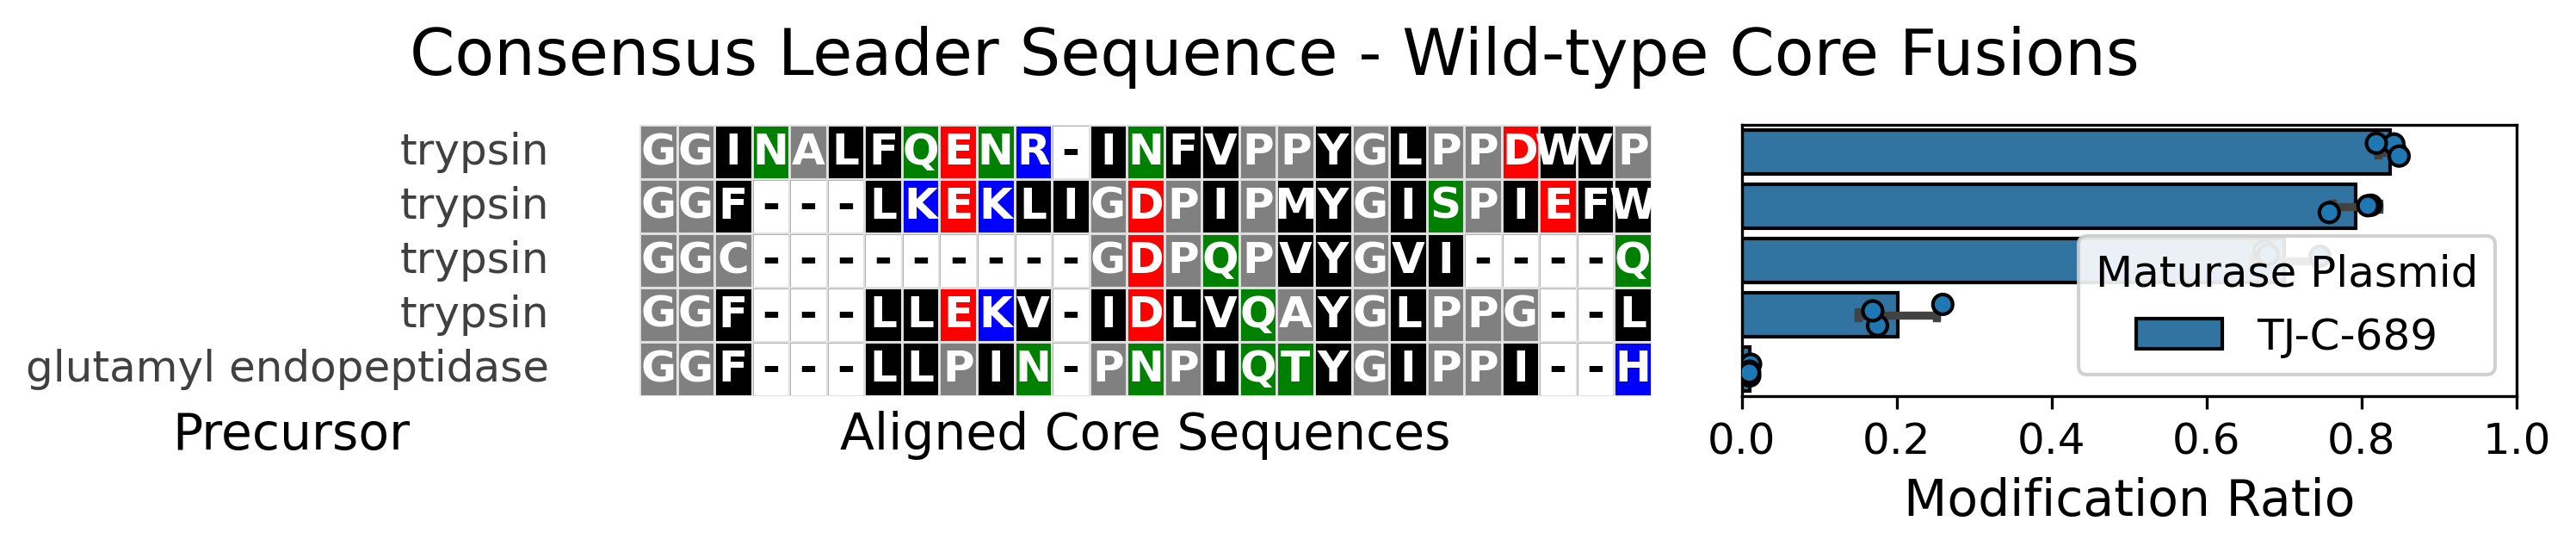

In [14]:
create_grouped_alignment_plot(
    hyella_plot_compare[hyella_plot_compare["maturase_plasmid"] == "TJ-C-689"],
    ref_sequence="None",
    hue_column="maturase_plasmid",
    metadata_cols=["digestion", "core"],
    color_scheme_name="hydrophobicity",
    show_ddg=False,
    show_gaps=True,
    preset="poster",
    savepath="summary_data_files/flask_wild_type_consensus_hyella.eps",
    use_alignment=True,
    drop_identical=False,
    metatitle="Precursor",
    seqtitle="Aligned Core Sequences",
    suptitle=r"Consensus Leader Sequence - Wild-type Core Fusions",
    sequence_column="full_core_sequence",
)

**Native precursors (`TJ-C-560`)** — native precursor peptides from the cluster.

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


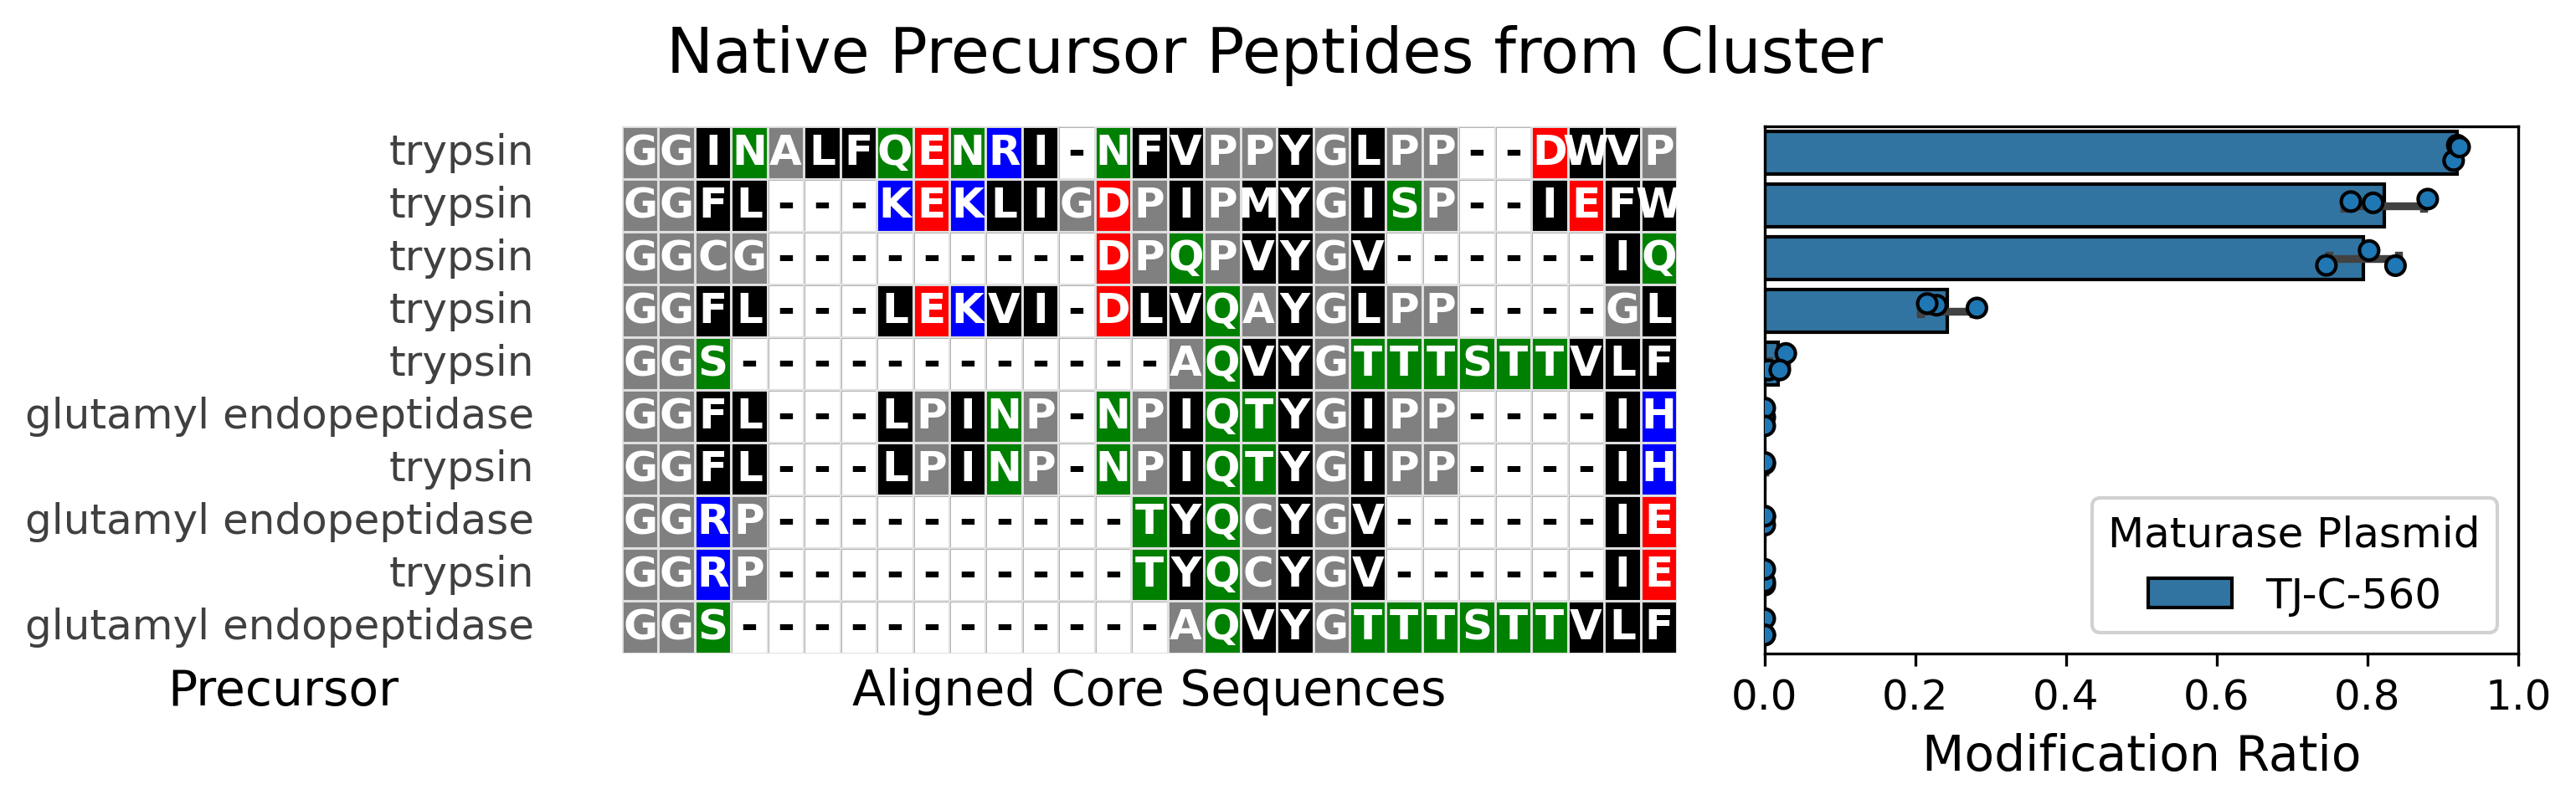

In [15]:
create_grouped_alignment_plot(
    hyella_plot_compare[hyella_plot_compare["maturase_plasmid"] == "TJ-C-560"],
    ref_sequence="None",
    hue_column="maturase_plasmid",
    metadata_cols=["digestion", "core"],
    color_scheme_name="hydrophobicity",
    show_ddg=False,
    show_gaps=True,
    preset="poster",
    savepath="summary_data_files/flask_wild_type_wild_hyella.eps",
    use_alignment=True,
    drop_identical=False,
    metatitle="Precursor",
    seqtitle="Aligned Core Sequences",
    suptitle=r"Native Precursor Peptides from Cluster",
    sequence_column="full_core_sequence",
)

### 5e. Full decided-on overview

Every kept feature at once, grouped by solubility tag · leader · core and coloured
by maturase plasmid.

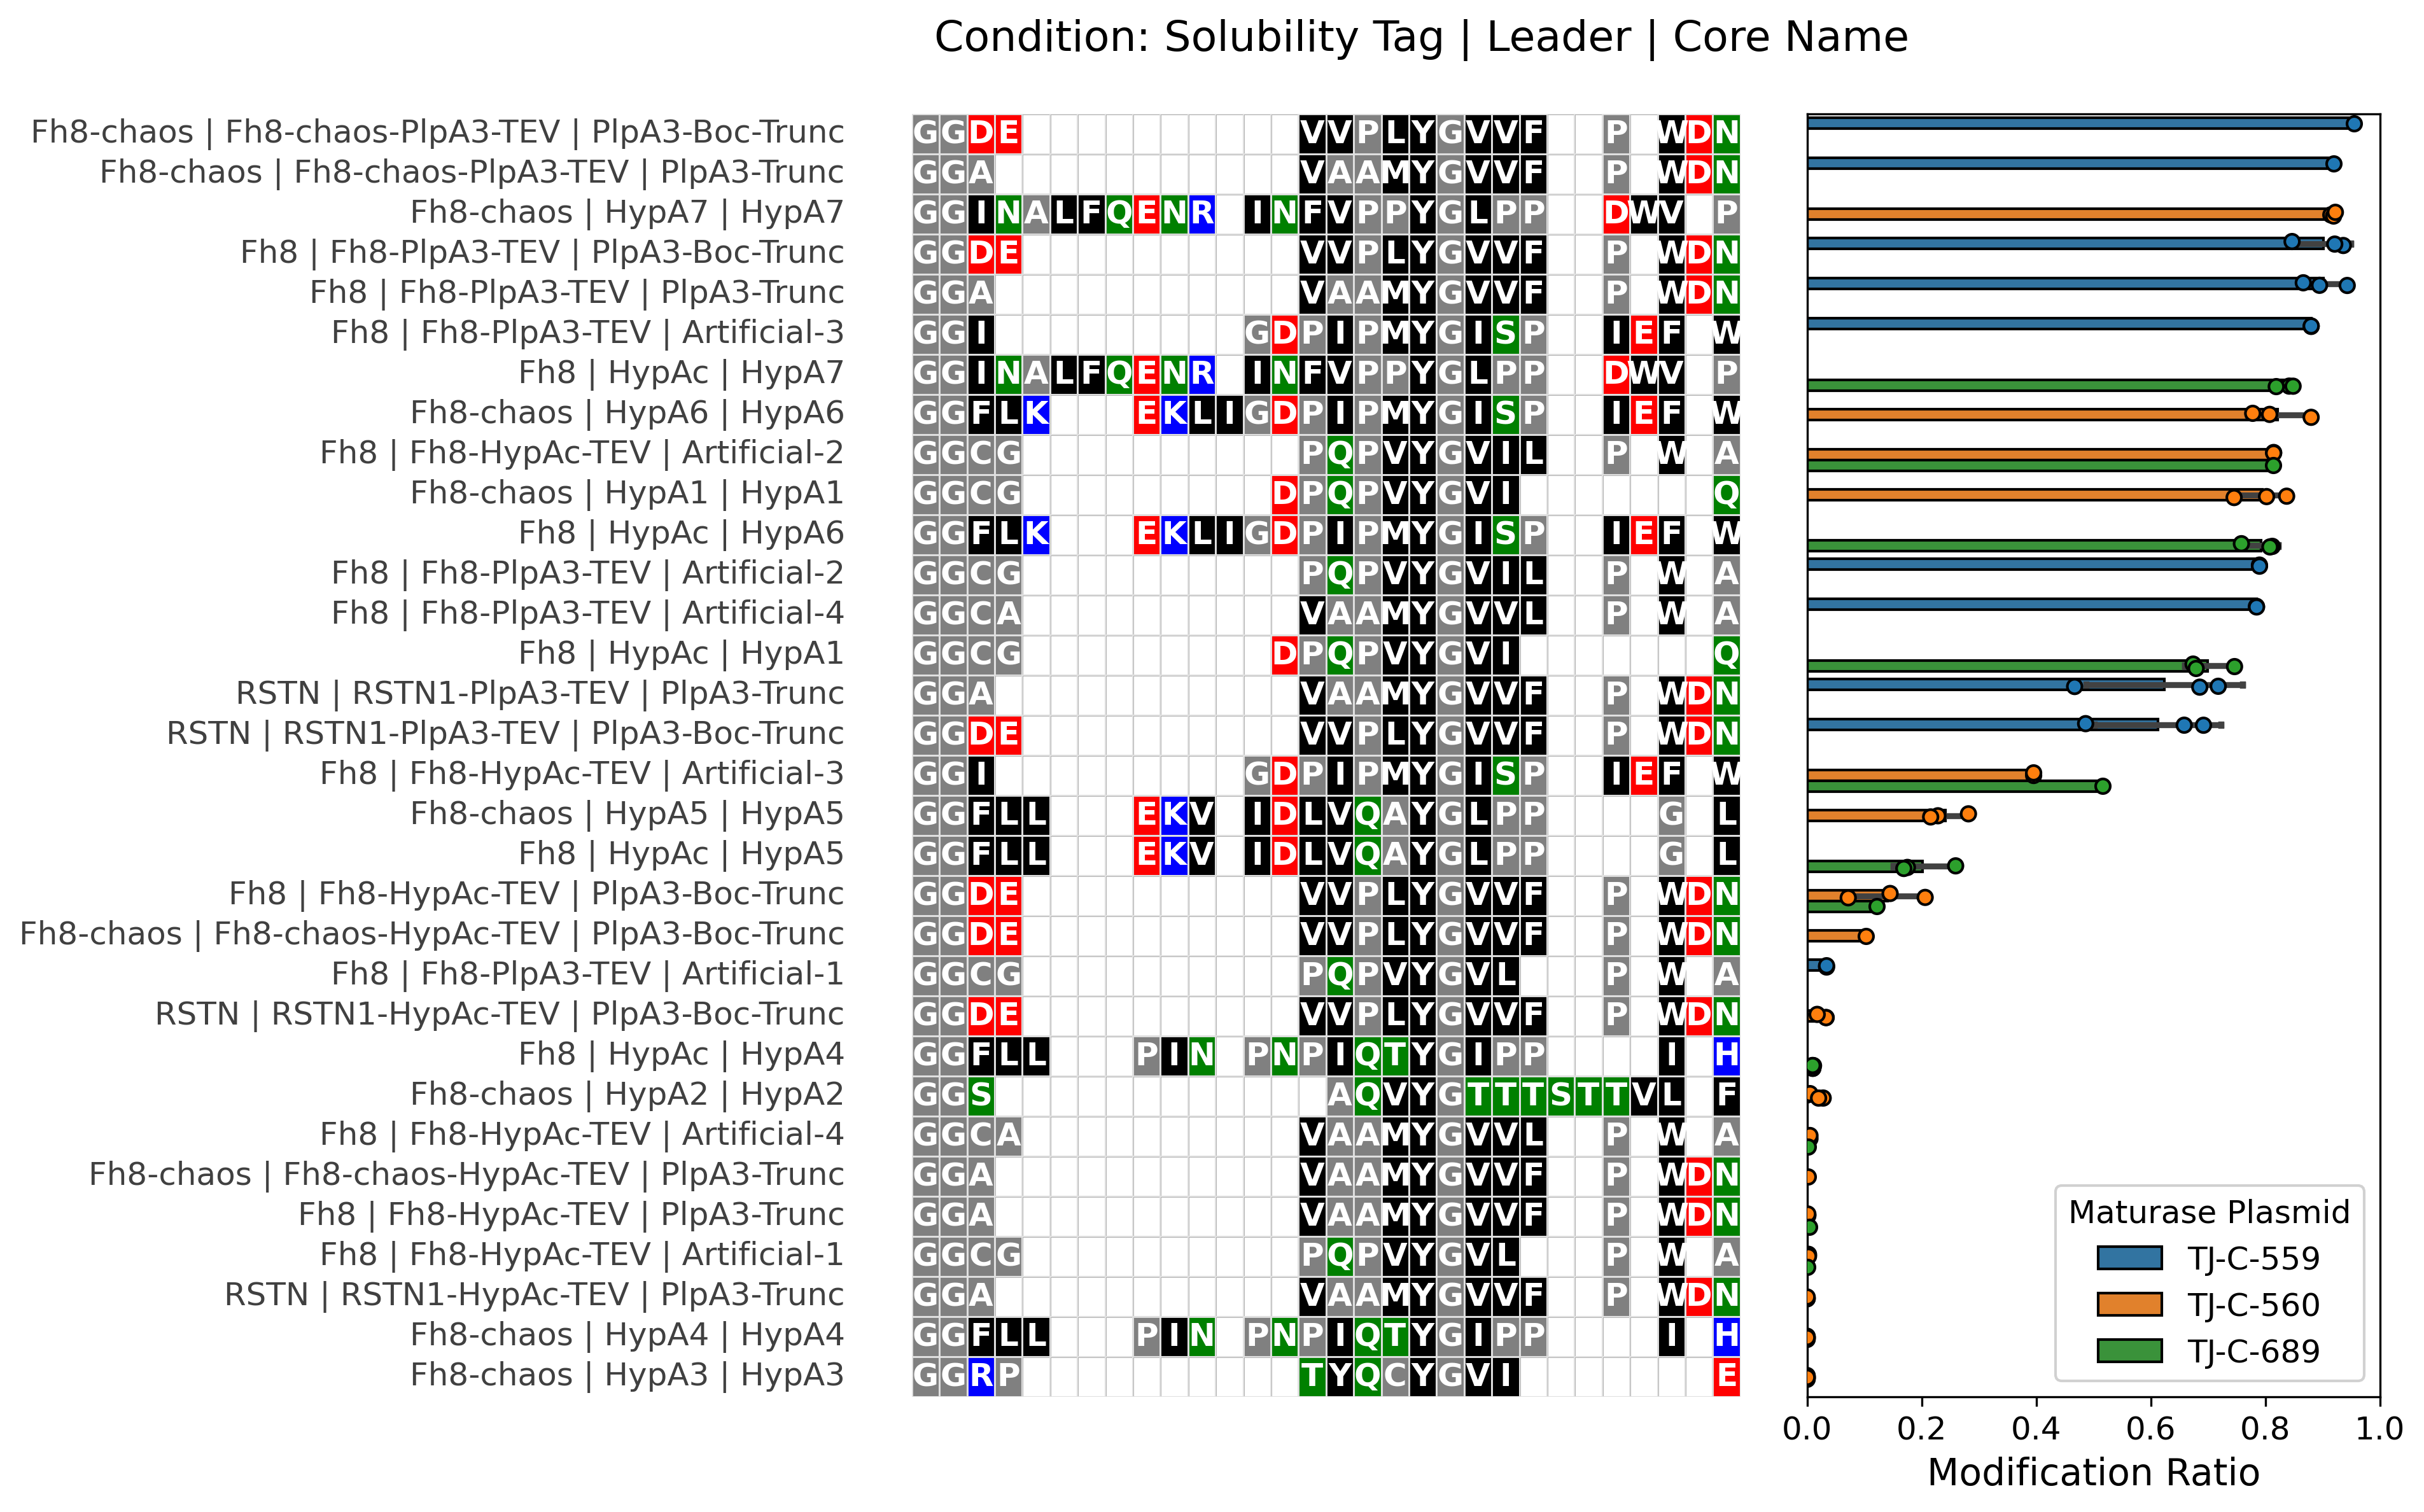

In [16]:
create_grouped_alignment_plot(
    kept_ratios_df,
    ref_sequence="None",
    hue_column="maturase_plasmid",
    metadata_cols=["solubility_tag", "leader", "core_name"],
    color_scheme_name="hydrophobicity",
    show_ddg=False,
    preset="poster",
    savepath=None,
    use_alignment=True,
    drop_identical=False,
    sequence_column="full_core_sequence",
)

## 6. SI report

For every kept group, in `ordered_source_file_list` order,
`generate_and_combine_simple_si_reports()`:

1. picks the single best (fragment_cut, charge),
2. plots only the manually curated peaks at that cut/charge (undetected replicates
   are listed as stubs, not plotted),
3. writes one A4 PDF page per group next to its pickle, with a running page number, and
4. merges them all into `COMBINED_SI_PDF_PATH`.

Page order, page numbers, and the combined-document order all follow
`ordered_source_file_list` exactly.

In [17]:
combined_si_pdf_path = generate_and_combine_simple_si_reports(
    ordered_source_file_list,
    COMBINED_SI_PDF_PATH,
    appendix_name="SI Appendix A",
    layout="beta",
    rt_range=(3, 15),
    break_axis=True,
    footer=False,
)
print(f"Combined SI report written to: {combined_si_pdf_path}")

Generating 'simple'-style SI reports for 49 group file(s), in the order given.
Successfully loaded ReplicateGroupResults from: D:\Spliceotide_Data_Analysis\output_reports_flasks\wild_type_hyella_peptides_TJ-C-593_HypX-HypY_TJ-C-560_24_trypsin\wild_type_hyella_peptides_TJ-C-593_HypX-HypY_TJ-C-560_24_trypsin_manually_reviewed.pkl.gz
Spectral data for 'unique_sample_1_wild_type_hyella_peptides' successfully loaded from cache.
  Wrote: D:\Spliceotide_Data_Analysis\output_reports_flasks\wild_type_hyella_peptides_TJ-C-593_HypX-HypY_TJ-C-560_24_trypsin\001_wild_type_hyella_peptides_TJ-C-593_HypX-HypY_TJ-C-560_24_trypsin_SI_Appendix_A_Figure_1_beta_Cut_(175,_195)_z2.pdf  (1 page(s), starting at page 1)
Successfully loaded ReplicateGroupResults from: D:\Spliceotide_Data_Analysis\output_reports_flasks\wild_type_hyella_peptides_TJ-C-594_HypX-HypY_TJ-C-560_24_glutamyl_endopeptidase\wild_type_hyella_peptides_TJ-C-594_HypX-HypY_TJ-C-560_24_glutamyl_endopeptidase_manually_reviewed.pkl.gz
Spectral dat

## 7. Filtered-out data

The plasmids that were **not** in `KEEP_PLASMIDS` are plotted here with the same
grouped-alignment bar plot, so nothing that was loaded is silently lost. Edit
`KEEP_PLASMIDS` in Section 1 to promote any of these into the main analysis.

15 filtered-out plasmid(s): ['TJ-C-585', 'TJ-C-586', 'TJ-C-587', 'TJ-C-588', 'TJ-C-589', 'TJ-C-590', 'TJ-C-591', 'TJ-C-592', 'TJ-C-706', 'TJ-C-707', 'TJ-C-708', 'TJ-C-710', 'TJ-C-711', 'TJ-C-712', 'TJ-C-713']


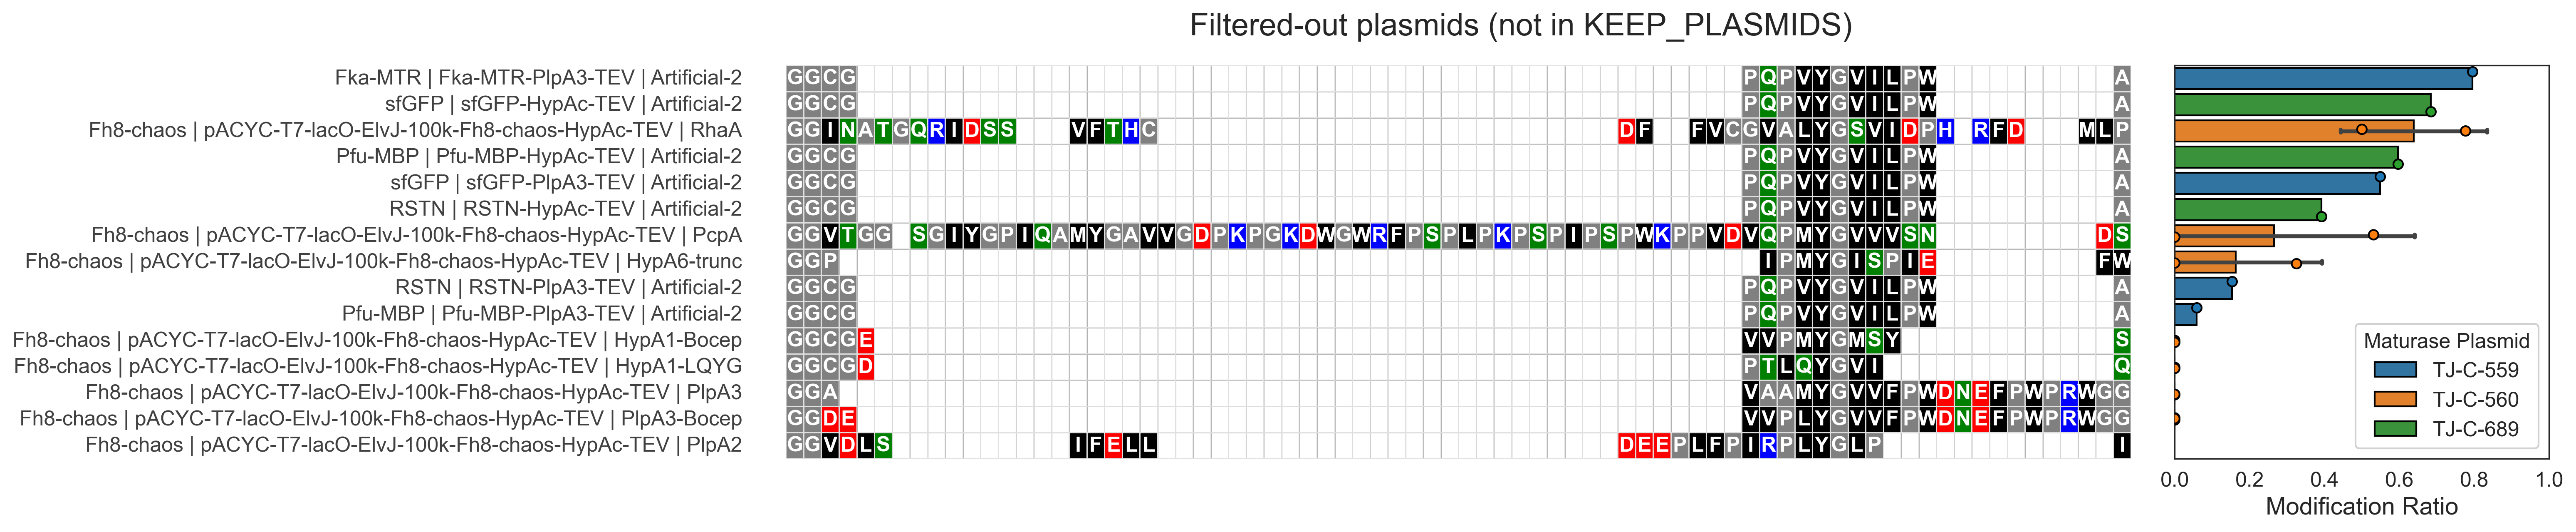

In [18]:
if dropped_ratios_df.empty:
    print("No filtered-out plasmids — every loaded group is in the keep-list.")
else:
    dropped_plasmids = sorted(dropped_ratios_df["precursor_plasmid"].dropna().unique())
    print(f"{len(dropped_plasmids)} filtered-out plasmid(s): {dropped_plasmids}")

    create_grouped_alignment_plot(
        dropped_ratios_df,
        ref_sequence="None",
        hue_column="maturase_plasmid",
        metadata_cols=["solubility_tag", "leader", "core_name"],
        color_scheme_name="hydrophobicity",
        show_ddg=False,
        preset="poster",
        savepath=None,
        use_alignment=True,
        drop_identical=False,
        suptitle="Filtered-out plasmids (not in KEEP_PLASMIDS)",
        sequence_column="full_core_sequence",
    )

## 8. Appendix — helpers & single-peak inspection

Utilities and dormant snippets kept for reference. Nothing here runs as part of
the main pipeline.

### 8a. `prepare_dataframe_for_plotting` (legacy)

Legacy compatibility shim that maps alternative column names / fills defaults for
the strict plotting functions. `master_df` already ships with the expected
columns, so this is unused by the pipeline above — retained in case an older
report format needs re-plotting.

In [19]:
def prepare_dataframe_for_plotting(df: pd.DataFrame) -> pd.DataFrame:
    """Guarantee that columns / categorical fields match the strict expectations
    of the calculation and alignment plotting functions."""
    plot_df = df.copy()

    # Map alternative column names onto the strict expected names.
    column_mappings = {
        "group_name": "experiment_id",
        "peak_area": "area",
        "target_sequence": "peptide_sequence",
        "cluster_id": "cut_id",
    }
    for old_col, new_col in column_mappings.items():
        if old_col in plot_df.columns and new_col not in plot_df.columns:
            plot_df[new_col] = plot_df[old_col]

    if "target_sequence" not in plot_df.columns and "peptide_sequence" in plot_df.columns:
        plot_df["target_sequence"] = plot_df["peptide_sequence"]

    # Curated data → treat everything as accepted "Gold" if no tier column present.
    if "tier" not in plot_df.columns:
        plot_df["tier"] = "Gold"

    # Modification string conversions expected by the calculator loop.
    if "target_modifications" in plot_df.columns:
        plot_df["modification_state"] = plot_df["target_modifications"].astype(str).replace({
            "{'unmodified': None}": "{'unmodified': None}",
            "unmodified": "{'unmodified': None}",
        })
    elif "modification_state" not in plot_df.columns:
        plot_df["modification_state"] = "{'unmodified': None}"

    # Final safety fallbacks for columns that must exist.
    required_cols = ["experiment_id", "sample_id", "peptide_sequence", "cut_id",
                     "enzyme", "precursor_name", "area"]
    for col in required_cols:
        if col not in plot_df.columns:
            plot_df[col] = "N/A" if col != "area" else 0.0

    return plot_df

### 8b. `collect_peaks` — pull peaks off a loaded group

Flatten `group.<which>_peaks` into a DataFrame that keeps the live `PeptidePeak`
(`peak`) and `TargetPeptide` (`target`) objects for QC / plotting, e.g.
`collect_peaks(g, "found", charge=2, tier="Gold")`.

In [20]:
def collect_peaks(group, which="selected", **filters):
    """DataFrame of every peak in group.<which>_peaks across all replicates, keeping the live
    PeptidePeak in 'peak' and the TargetPeptide in 'target' for QC.
    which in {'selected','found','all_found'}. getattr-safe (found peaks may lack tier/metrics).
    Optional exact-match filters, e.g. collect_peaks(g,'found', charge=2, tier='Gold')."""
    rows = []
    for rep_id, ar in group.replicates.items():
        for tgt, peaks in (getattr(ar, f"{which}_peaks", {}) or {}).items():
            for pk in peaks:
                qm = getattr(pk, "quality_metrics", {}) or {}
                rows.append({
                    "replicate": rep_id, "sequence": getattr(tgt, "sequence", None),
                    "fragment_cut": getattr(tgt, "fragment_cut", None),
                    "modifications": str(getattr(tgt, "modifications", None)),
                    "charge": getattr(pk, "charge", None), "rt": getattr(pk, "rt", None),
                    "trapz_area": getattr(pk, "trapz_area", None), "tier": getattr(pk, "tier", None),
                    "quality_score": getattr(pk, "quality_score", None),
                    "overall_pass": qm.get("overall_pass"), "is_stub": getattr(pk, "is_stub", None),
                    "peak": pk, "target": tgt,   # <-- the live objects
                })
    df = pd.DataFrame(rows)
    for k, v in filters.items():
        df = df[df[k] == v]
    return df.reset_index(drop=True)

### 8c. Single-group MS² inspection (dormant examples)

Reference snippets for drilling into one group's peaks / MS² multipanels. Kept as
raw strings so they never execute on a run-all; copy into a fresh cell and adapt
the paths to use.

In [21]:
# EXTRA ANALYSIS — TJ-C-616 with HypX-HypY / TJ-C-689 (glutamyl endopeptidase)
_example_tjc616 = r"""
TJ_C_689_TJ_C_616 = ReplicateGroupResults.load(
    r'D:\Spliceotide_Data_Analysis\output_reports_flasks'
    r'\wild_type_consensus_hyella_peptides_TJ-C-616_HypX-HypY_TJ-C-689_24_glutamyl_endopeptidase'
    r'\wild_type_consensus_hyella_peptides_TJ-C-616_HypX-HypY_TJ-C-689_24_glutamyl_endopeptidase_manually_reviewed.pkl.gz')
TJ_C_689_TJ_C_616_matrix = TJ_C_689_TJ_C_616.generate_modification_state_matrix()
TJ_C_689_TJ_C_616_found = collect_peaks(TJ_C_689_TJ_C_616, "found")
TJ_C_689_TJ_C_616_found.loc[6, "peak"].plot_peak()
TJ_C_689_TJ_C_616_selected = collect_peaks(TJ_C_689_TJ_C_616, "selected")
TJ_C_689_TJ_C_616_selected.loc[0, "peak"].plot_peak()
"""

In [22]:
# EXTRA ANALYSIS — TJ-C-617 with HypX-HypY / TJ-C-689: MS2 multipanels
_example_tjc617 = r"""
import plotting_analysis_functions
TJ_C_689_TJ_C_617 = analysis_containers.ReplicateGroupResults.load(
    r'D:\Spliceotide_Data_Analysis\output_reports_flasks'
    r'\wild_type_consensus_hyella_peptides_TJ-C-617_HypX-HypY_TJ-C-689_24_glutamyl_endopeptidase'
    r'\wild_type_consensus_hyella_peptides_TJ-C-617_HypX-HypY_TJ-C-689_24_glutamyl_endopeptidase_manually_reviewed.pkl.gz')
TJ_C_689_TJ_C_617_matrix = TJ_C_689_TJ_C_617.generate_modification_state_matrix()
TJ_C_689_TJ_C_617_found = collect_peaks(TJ_C_689_TJ_C_617, "found")
TJ_C_689_TJ_C_617_selected = collect_peaks(TJ_C_689_TJ_C_617, "selected")

rep = "wild_type_consensus_hyella_peptides_TJ-C-617_HypX-HypY_TJ-C-689_24_glutamyl_endopeptidase_Rep_3"

# combine the per-state MS2 panels (mirror + sequence) into ONE labeled figure
fig, path = plotting_analysis_functions.plot_si_ms2_multipanel(
    TJ_C_689_TJ_C_617, rep, (172, 196), 3)          # 3 detected states -> summary_data_files/

# force all FOUR theoretical states (undetected drawn as "No MS2 detected" placeholders):
fig, path = plotting_analysis_functions.plot_si_ms2_multipanel(
    TJ_C_689_TJ_C_617, rep, (172, 196), 2, include_undetected=True)
"""